In [19]:
import pandas as pd

print("Healthcare analytics project started successfully!")

Healthcare analytics project started successfully!


In [20]:
import pandas as pd
import os

print(os.listdir("/content"))

['.config', 'long_stay_by_department.png', 'Hospital_Analytics_Project_2.csv', 'average_pain_by_stay_group.png', 'sample_data']


In [21]:
import pandas as pd

df = pd.read_csv("/content/Hospital_Analytics_Project_2.csv")

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset loaded successfully!
Number of rows and columns: (5000, 11)

Column names:
['Encounter_ID', 'Patient_ID', 'Age', 'Gender', 'Diagnosis', 'Department', 'Length_of_Stay', 'Pain_Score', 'Admission_Date', 'Discharge_Date', 'Calculated_LOS']

First 5 rows:


,Encounter_ID,Patient_ID,Age,Gender,Diagnosis,Department,Length_of_Stay,Pain_Score,Admission_Date,Discharge_Date,Calculated_LOS
0,E00001,P03175,49,Male,Diabetes,General Medicine,5,5.3,2025-09-11,2025-09-16,5
1,E00002,P00861,76,Male,Heart Failure,Cardiology,6,2.7,2025-01-01,2025-01-07,6
2,E00003,P01295,51,Female,COPD,Pulmonology,4,6.4,2025-05-28,2025-06-01,4
3,E00004,P01131,26,Male,COPD,Pulmonology,8,4.0,2025-12-30,2026-01-07,8
4,E00005,P01096,28,Male,Pneumonia,Pulmonology,11,1.9,2025-06-08,2025-06-19,11


In [22]:
print("Dataset shape:", df.shape)

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDuplicate encounter IDs:")
print(df["Encounter_ID"].duplicated().sum())

print("\nDuplicate complete rows:")
print(df.duplicated().sum())

Dataset shape: (5000, 11)

Missing values in each column:
Encounter_ID      0
Patient_ID        0
Age               0
Gender            0
Diagnosis         0
Department        0
Length_of_Stay    0
Pain_Score        0
Admission_Date    0
Discharge_Date    0
Calculated_LOS    0
dtype: int64

Duplicate encounter IDs:
0

Duplicate complete rows:
0


In [23]:
print("Duplicate encounter IDs:",
      df["Encounter_ID"].duplicated().sum())

print("Duplicate complete rows:",
      df.duplicated().sum())

print("Length-of-stay mismatches:",
      (df["Length_of_Stay"] != df["Calculated_LOS"]).sum())

Duplicate encounter IDs: 0
Duplicate complete rows: 0
Length-of-stay mismatches: 0


In [24]:
# Convert dates into proper date format
df["Admission_Date"] = pd.to_datetime(df["Admission_Date"])
df["Discharge_Date"] = pd.to_datetime(df["Discharge_Date"])

print("Admission after discharge:",
      (df["Admission_Date"] > df["Discharge_Date"]).sum())

print("Negative length of stay:",
      (df["Calculated_LOS"] < 0).sum())

print("Age below 0 or above 120:",
      ((df["Age"] < 0) | (df["Age"] > 120)).sum())

print("Pain score outside 0–10:",
      ((df["Pain_Score"] < 0) | (df["Pain_Score"] > 10)).sum())

Admission after discharge: 0
Negative length of stay: 0
Age below 0 or above 120: 0
Pain score outside 0–10: 0


In [25]:
print("Total encounters:", len(df))

print("Unique patients:", df["Patient_ID"].nunique())

print("Average length of stay:",
      round(df["Calculated_LOS"].mean(), 2), "days")

print("Average pain score:",
      round(df["Pain_Score"].mean(), 2))

print("Total diagnoses:", df["Diagnosis"].nunique())

print("Total departments:", df["Department"].nunique())

Total encounters: 5000
Unique patients: 2603
Average length of stay: 6.61 days
Average pain score: 4.75
Total diagnoses: 8
Total departments: 5


In [26]:
# Identify encounters lasting more than 14 days
df["Long_Stay"] = df["Calculated_LOS"] > 14

long_stay_count = df["Long_Stay"].sum()
long_stay_percentage = df["Long_Stay"].mean() * 100

print("Long-stay encounters:", long_stay_count)
print("Long-stay percentage:",
      round(long_stay_percentage, 2), "%")

Long-stay encounters: 180
Long-stay percentage: 3.6 %


In [27]:
department_analysis = (
    df.groupby("Department")
      .agg(
          Total_Encounters=("Encounter_ID", "count"),
          Long_Stay_Encounters=("Long_Stay", "sum")
      )
      .reset_index()
)

department_analysis["Long_Stay_Percentage"] = (
    department_analysis["Long_Stay_Encounters"]
    / department_analysis["Total_Encounters"] * 100
)

department_analysis = department_analysis.sort_values(
    "Long_Stay_Percentage", ascending=False
)

print(department_analysis.round(2).to_string(index=False))


      Department  Total_Encounters  Long_Stay_Encounters  Long_Stay_Percentage
       Neurology               613                    82                 13.38
     Orthopedics              1832                    98                  5.35
      Cardiology               605                     0                  0.00
General Medicine               645                     0                  0.00
     Pulmonology              1305                     0                  0.00


In [28]:
diagnosis_analysis = (
    df.groupby("Diagnosis")
      .agg(
          Total_Encounters=("Encounter_ID", "count"),
          Long_Stay_Encounters=("Long_Stay", "sum")
      )
      .reset_index()
)

diagnosis_analysis["Long_Stay_Percentage"] = (
    diagnosis_analysis["Long_Stay_Encounters"]
    / diagnosis_analysis["Total_Encounters"] * 100
)

diagnosis_analysis = diagnosis_analysis.sort_values(
    "Long_Stay_Percentage", ascending=False
)

print(diagnosis_analysis.round(2).to_string(index=False))

          Diagnosis  Total_Encounters  Long_Stay_Encounters  Long_Stay_Percentage
           Fracture               628                    98                 15.61
             Stroke               613                    82                 13.38
           Diabetes               645                     0                  0.00
               COPD               674                     0                  0.00
      Heart Failure               605                     0                  0.00
Knee Osteoarthritis               570                     0                  0.00
      Low Back Pain               634                     0                  0.00
          Pneumonia               631                     0                  0.00


In [29]:
department_diagnosis = (
    df.groupby(["Department", "Diagnosis"])
      .agg(
          Total_Encounters=("Encounter_ID", "count"),
          Long_Stay_Encounters=("Long_Stay", "sum")
      )
      .reset_index()
)

department_diagnosis["Long_Stay_Percentage"] = (
    department_diagnosis["Long_Stay_Encounters"]
    / department_diagnosis["Total_Encounters"] * 100
)

department_diagnosis = department_diagnosis.sort_values(
    "Long_Stay_Encounters", ascending=False
)

print(
    department_diagnosis[
        department_diagnosis["Long_Stay_Encounters"] > 0
    ].round(2).to_string(index=False)
)

 Department Diagnosis  Total_Encounters  Long_Stay_Encounters  Long_Stay_Percentage
Orthopedics  Fracture               628                    98                 15.61
  Neurology    Stroke               613                    82                 13.38


In [30]:
stay_comparison = (
    df.groupby("Long_Stay")
      .agg(
          Total_Encounters=("Encounter_ID", "count"),
          Average_Age=("Age", "mean"),
          Average_Pain=("Pain_Score", "mean"),
          Average_LOS=("Calculated_LOS", "mean")
      )
      .reset_index()
)

stay_comparison["Stay_Group"] = stay_comparison["Long_Stay"].map({
    False: "Non-long-stay (14 days or less)",
    True: "Long-stay (more than 14 days)"
})

print(stay_comparison.round(2).to_string(index=False))

 Long_Stay  Total_Encounters  Average_Age  Average_Pain  Average_LOS                      Stay_Group
     False              4820        54.45          4.72         6.28 Non-long-stay (14 days or less)
      True               180        51.44          5.64        15.51   Long-stay (more than 14 days)


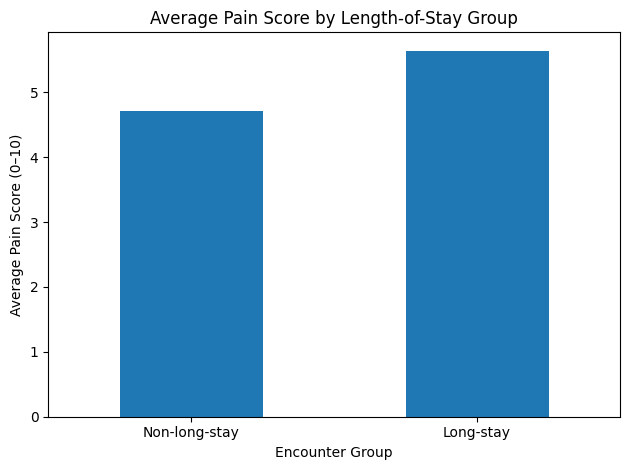

In [31]:
import matplotlib.pyplot as plt

pain_comparison = df.groupby("Long_Stay")["Pain_Score"].mean()

pain_comparison.index = [
    "Non-long-stay",
    "Long-stay"
]

pain_comparison.plot(kind="bar")

plt.title("Average Pain Score by Length-of-Stay Group")
plt.xlabel("Encounter Group")
plt.ylabel("Average Pain Score (0–10)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [32]:
from scipy.stats import mannwhitneyu

long_stay_pain = df.loc[
    df["Long_Stay"], "Pain_Score"
]

non_long_stay_pain = df.loc[
    ~df["Long_Stay"], "Pain_Score"
]

statistic, p_value = mannwhitneyu(
    long_stay_pain,
    non_long_stay_pain,
    alternative="two-sided"
)

print("Mann-Whitney U statistic:", statistic)
print("P-value:", p_value)

Mann-Whitney U statistic: 548842.0
P-value: 1.4423605865118603e-09


In [33]:
from scipy.stats import mannwhitneyu

for diagnosis in ["Fracture", "Stroke"]:

    subset = df[df["Diagnosis"] == diagnosis]

    long_pain = subset.loc[
        subset["Long_Stay"], "Pain_Score"
    ]

    non_long_pain = subset.loc[
        ~subset["Long_Stay"], "Pain_Score"
    ]

    u_stat, p_value = mannwhitneyu(
        long_pain,
        non_long_pain,
        alternative="two-sided"
    )

    print("\nDiagnosis:", diagnosis)
    print("Long-stay average pain:", round(long_pain.mean(), 2))
    print("Non-long-stay average pain:", round(non_long_pain.mean(), 2))
    print("P-value:", round(p_value, 4))


Diagnosis: Fracture
Long-stay average pain: 6.65
Non-long-stay average pain: 6.47
P-value: 0.2785

Diagnosis: Stroke
Long-stay average pain: 4.44
Non-long-stay average pain: 4.54
P-value: 0.389


In [34]:
print("HEALTHCARE PATIENT ANALYTICS PROJECT")
print("=" * 40)

print(f"Total encounters: {df['Encounter_ID'].nunique()}")
print(f"Unique patients: {df['Patient_ID'].nunique()}")
print(f"Average length of stay: {df['Calculated_LOS'].mean():.2f} days")
print(f"Average pain score: {df['Pain_Score'].mean():.2f}/10")
print(f"Long-stay encounters: {df['Long_Stay'].sum()}")
print(f"Long-stay percentage: {df['Long_Stay'].mean() * 100:.2f}%")

print("\nKEY FINDINGS")
print("-" * 40)
print("1. Neurology had a 13.38% long-stay rate.")
print("2. Fracture encounters had a 15.61% long-stay rate.")
print("3. Stroke encounters had a 13.38% long-stay rate.")
print("4. Long-stay encounters had a higher overall average pain score.")
print("5. Diagnosis-wise tests did not find statistically significant")
print("   pain-score distribution differences for Fracture or Stroke.")

print("\nNote: This is a synthetic dataset.")
print("Findings are educational and do not establish causation.")

HEALTHCARE PATIENT ANALYTICS PROJECT
Total encounters: 5000
Unique patients: 2603
Average length of stay: 6.61 days
Average pain score: 4.75/10
Long-stay encounters: 180
Long-stay percentage: 3.60%

KEY FINDINGS
----------------------------------------
1. Neurology had a 13.38% long-stay rate.
2. Fracture encounters had a 15.61% long-stay rate.
3. Stroke encounters had a 13.38% long-stay rate.
4. Long-stay encounters had a higher overall average pain score.
5. Diagnosis-wise tests did not find statistically significant
   pain-score distribution differences for Fracture or Stroke.

Note: This is a synthetic dataset.
Findings are educational and do not establish causation.


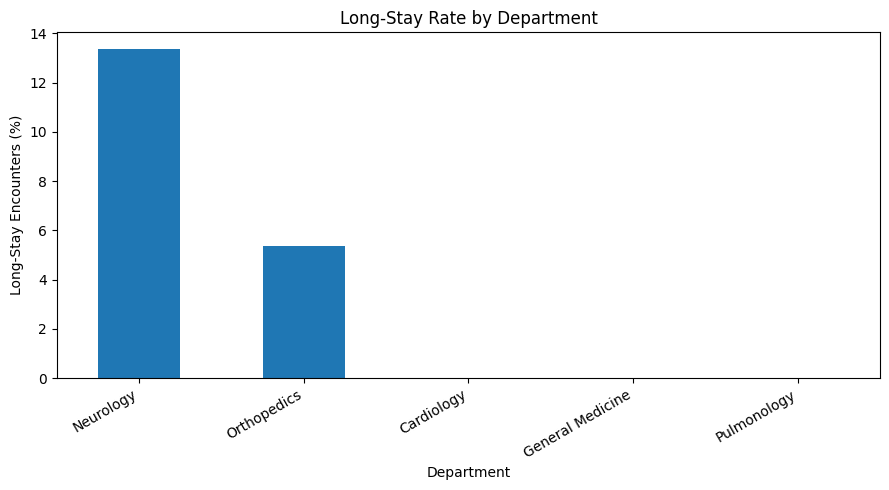

In [35]:
import matplotlib.pyplot as plt

dept_chart = (
    df.groupby("Department")["Long_Stay"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
dept_chart.plot(kind="bar")
plt.title("Long-Stay Rate by Department")
plt.xlabel("Department")
plt.ylabel("Long-Stay Encounters (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("long_stay_by_department.png", dpi=300)
plt.show()

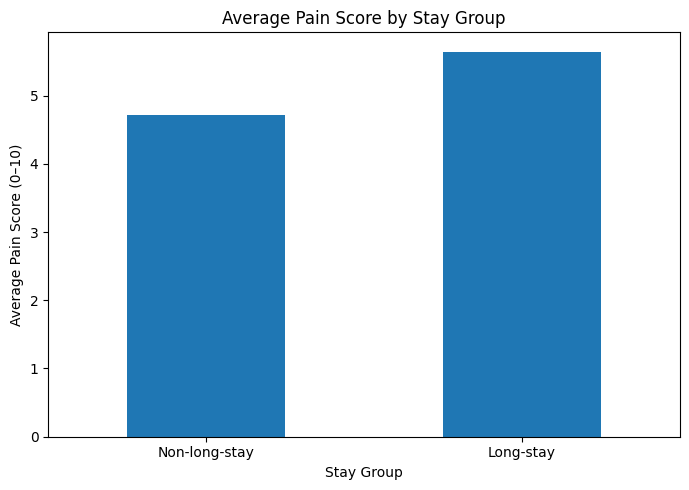

In [36]:
pain_chart = df.groupby("Long_Stay")["Pain_Score"].mean()
pain_chart.index = ["Non-long-stay", "Long-stay"]

plt.figure(figsize=(7, 5))
pain_chart.plot(kind="bar")
plt.title("Average Pain Score by Stay Group")
plt.xlabel("Stay Group")
plt.ylabel("Average Pain Score (0–10)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("average_pain_by_stay_group.png", dpi=300)
plt.show()